# 01 · Exploratory data analysis: HI-Small

Goal: confirm the raw schema, label rates and value domains before writing any dbt model, and pick the
time windows used for features and the train/test split.

Everything runs in DuckDB directly over the raw CSV, so nothing is loaded fully into pandas.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
con = duckdb.connect()

## Raw header

The header repeats `Account` twice (sender account, then receiver account). Reading by name would silently
produce `Account` and `Account_1`, so the schema is declared by position.

In [2]:
print((RAW / "HI-Small_Trans.csv").open().readline())

Timestamp,From Bank,Account,To Bank,Account,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering



In [3]:
con.execute(f"""
create view tx as
select *, strptime(ts, '%Y/%m/%d %H:%M') as transaction_ts
from read_csv('{RAW / "HI-Small_Trans.csv"}', header = true, columns = {{
    'ts': 'VARCHAR', 'from_bank': 'VARCHAR', 'from_account': 'VARCHAR',
    'to_bank': 'VARCHAR', 'to_account': 'VARCHAR', 'amount_received': 'DOUBLE',
    'receiving_currency': 'VARCHAR', 'amount_paid': 'DOUBLE', 'payment_currency': 'VARCHAR',
    'payment_format': 'VARCHAR', 'is_laundering': 'INTEGER'}})
""")
con.sql("select * from tx limit 5").df()

,ts,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering,transaction_ts
0,2022/09/01 00:20,010,8000EBD30,010,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0,2022-09-01 00:20:00
1,2022/09/01 00:20,03208,8000F4580,001,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0,2022-09-01 00:20:00
2,2022/09/01 00:00,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0,2022-09-01 00:00:00
3,2022/09/01 00:02,012,8000F5030,012,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0,2022-09-01 00:02:00
4,2022/09/01 00:06,010,8000F5200,010,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0,2022-09-01 00:06:00


Bank codes are kept as text: values such as `010` and `03208` carry leading zeros.

## Size and label rate

In [4]:
con.sql("""
select count(*) as transactions,
       sum(is_laundering) as laundering_tx,
       round(100 * avg(is_laundering), 3) as laundering_pct,
       min(transaction_ts) as first_ts,
       max(transaction_ts) as last_ts
from tx
""").df()

,transactions,laundering_tx,laundering_pct,first_ts,last_ts
0,5078345,5177.0,0.102,2022-09-01,2022-09-18 16:18:00


## Daily volume

This is the most important table in the notebook.

In [5]:
daily = con.sql("""
select cast(transaction_ts as date) as day, count(*) as transactions,
       sum(is_laundering) as laundering_tx, round(100 * avg(is_laundering), 3) as laundering_pct
from tx group by 1 order by 1
""").df()
daily

,day,transactions,laundering_tx,laundering_pct
0,2022-09-01,1114921,322.0,0.029
1,2022-09-02,754449,408.0,0.054
2,2022-09-03,207382,391.0,0.189
3,2022-09-04,207430,407.0,0.196
4,2022-09-05,482650,471.0,0.098
5,2022-09-06,482089,531.0,0.110
6,2022-09-07,482751,497.0,0.103
7,2022-09-08,482773,539.0,0.112
8,2022-09-09,654467,514.0,0.079
9,2022-09-10,208325,442.0,0.212


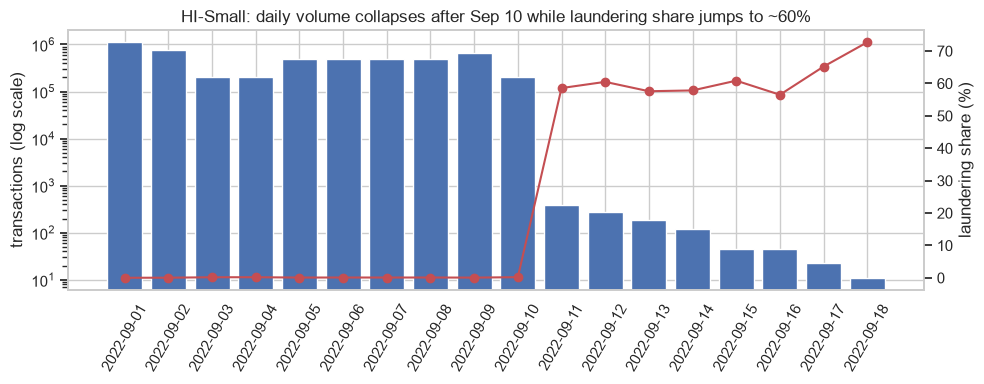

In [6]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(daily.day.astype(str), daily.transactions, color="#4C72B0")
ax1.set_yscale("log")
ax1.set_ylabel("transactions (log scale)")
ax2 = ax1.twinx()
ax2.plot(daily.day.astype(str), daily.laundering_pct, color="#C44E52", marker="o")
ax2.set_ylabel("laundering share (%)")
ax2.grid(False)
ax1.tick_params(axis="x", rotation=60)
ax1.set_title("HI-Small: daily volume collapses after Sep 10 while laundering share jumps to ~60%")
fig.tight_layout()
fig.savefig(FIG / "eda_daily_volume.png", dpi=150)

**Reading the chart**

- Sep 1–10 is the real simulation: 200k–1.1M transfers per day with a laundering share of 0.03–0.2%.
  Sep 3–4 and Sep 10 are weekends (lower volume).
- Sep 11–18 holds only ~1,100 transfers, ~60% of them laundering. These are laundering chains that were still
  running when normal activity stopped. A model trained or tested on these days would learn
  "active after Sep 10 means launderer", which says nothing about real monitoring.

**Decision:** the tail stays in the warehouse and on the dashboard (clearly labeled), but modeling uses
Sep 1–10 only.

## Accounts

In [7]:
con.sql("""
with sides as (
    select from_bank || '-' || from_account as account_id, is_laundering from tx
    union all
    select to_bank || '-' || to_account, is_laundering from tx
)
select count(distinct account_id) as accounts,
       count(distinct account_id) filter (where is_laundering = 1) as laundering_accounts,
       round(100 * laundering_accounts / accounts, 2) as laundering_account_pct,
       (select count(distinct from_account) from tx) as distinct_sender_ids_without_bank,
       (select count(distinct from_bank || '-' || from_account) from tx) as distinct_sender_ids_with_bank
from sides
""").df()

,accounts,laundering_accounts,laundering_account_pct,distinct_sender_ids_without_bank,distinct_sender_ids_with_bank
0,515088,6357,1.23,496995,496999


A handful of account ids repeat across banks, so the account key is `bank || '-' || account`.
About 1.2% of accounts touch at least one laundering transfer: that is the account-level positive rate.

## Value domains (feed dbt `accepted_values` tests)

In [8]:
con.sql("""
select payment_format, count(*) as n, sum(is_laundering) as laundering_tx,
       round(100 * avg(is_laundering), 3) as laundering_pct,
       count(*) filter (where payment_currency <> receiving_currency) as cross_currency
from tx group by 1 order by n desc
""").df()

,payment_format,n,laundering_tx,laundering_pct,cross_currency
0,Cheque,1864331,324.0,0.017,0
1,Credit Card,1323324,206.0,0.016,0
2,ACH,600797,4483.0,0.746,71582
3,Cash,490891,108.0,0.022,0
4,Reinvestment,481056,0.0,0.000,0
5,Wire,171855,0.0,0.000,588
6,Bitcoin,146091,56.0,0.038,0


In [9]:
con.sql("""
select c as currency, count(*) as n from (
    select receiving_currency as c from tx union all select payment_currency from tx
) group by 1 order by n desc
""").df()

,currency,n
0,US Dollar,3774513
1,Euro,2340314
2,Swiss Franc,472744
3,Yuan,420303
4,Shekel,387172
5,Rupee,382267
6,UK Pound,361993
7,Ruble,312539
8,Yen,311528
9,Bitcoin,294217


- 7 payment formats, 15 currencies (including Bitcoin).
- ACH carries ~87% of laundering transfers; Wire and Reinvestment carry none in HI-Small.
- Currency conversion happens only on ACH and Wire transfers.

## Data quality checks

In [10]:
con.sql("""
select
    count(*) filter (where amount_paid < 0 or amount_received < 0) as negative_amounts,
    count(*) filter (where payment_currency = receiving_currency and amount_paid <> amount_received)
        as same_currency_amount_mismatch,
    count(*) filter (where payment_currency <> receiving_currency) as cross_currency,
    count(*) filter (where from_bank = to_bank and from_account = to_account) as self_transfers,
    count(*) - (select count(*) from (select distinct * exclude (transaction_ts) from tx)) as exact_duplicates
from tx
""").df()

,negative_amounts,same_currency_amount_mismatch,cross_currency,self_transfers,exact_duplicates
0,0,0,72170,591212,9


- No negative amounts; same-currency transfers always have paid = received. Both become dbt tests.
- Self-transfers are common (mostly Reinvestment). They stay in the data, flagged, and are excluded from
  counterparty counts.
- 9 exact duplicate rows. With no natural transaction id, the partitioner hashes every field plus an ordinal
  among identical rows, which keeps all rows and still yields a unique, stable key.

## Implied exchange rates

Amounts must be comparable across currencies before computing totals and means. Every currency appears in
cross-currency transfers against US Dollar, so a USD rate per currency can be derived from the data itself
(median of received / paid). The dbt model `int_currency_rates` uses the same logic.

In [11]:
con.sql("""
select payment_currency as currency, median(amount_received / amount_paid) as usd_per_unit, count(*) as n
from tx
where receiving_currency = 'US Dollar' and payment_currency <> 'US Dollar' and amount_paid > 0
group by 1 order by 1
""").df()

,currency,usd_per_unit,n
0,Australian Dollar,0.707814,147
1,Bitcoin,11881.623158,13
2,Brazil Real,0.177101,81
3,Canadian Dollar,0.757978,560
4,Euro,1.171783,11060
5,Mexican Peso,0.047297,292
6,Ruble,0.012853,170
7,Rupee,0.013616,803
8,Saudi Riyal,0.266588,64
9,Shekel,0.296121,47


## Laundering typologies (patterns file)

In [12]:
import re
from datetime import datetime

attempts, current = [], None
for line in (RAW / "HI-Small_Patterns.txt").open():
    if line.startswith("BEGIN"):
        current = {"typology": re.search(r"- ([A-Z-]+)", line).group(1), "ts": []}
    elif line.startswith("END"):
        attempts.append(current)
    elif line[:2] == "20":
        current["ts"].append(datetime.strptime(line[:16], "%Y/%m/%d %H:%M"))

import pandas as pd
patterns = pd.DataFrame(
    {
        "typology": a["typology"],
        "transactions": len(a["ts"]),
        "span_days": (max(a["ts"]) - min(a["ts"])).total_seconds() / 86400,
    }
    for a in attempts
)
patterns.groupby("typology").agg(
    attempts=("typology", "size"),
    transactions=("transactions", "sum"),
    median_span_days=("span_days", "median"),
).sort_values("attempts", ascending=False)

,attempts,transactions,median_span_days
typology,,,
CYCLE,54,287,2.995139
GATHER-SCATTER,51,716,6.284028
BIPARTITE,49,263,1.013889
FAN-OUT,48,342,3.194097
SCATTER-GATHER,44,626,3.698611
STACK,43,466,3.054861
RANDOM,41,191,1.916667
FAN-IN,40,318,3.538889


In [13]:
print(f"attempts: {len(patterns)}, transactions in patterns: {patterns.transactions.sum():,}")
print(patterns.span_days.describe(percentiles=[0.5, 0.75, 0.9]).round(2))

attempts: 370, transactions in patterns: 3,209
count    370.00
mean       2.81
std        1.93
min        0.00
50%        3.11
75%        3.79
90%        4.59
max        8.43
Name: span_days, dtype: float64


- 370 attempts across 8 typologies; 3,209 transactions. The other ~1,950 laundering transfers are labeled
  but not attributed to a typology, so the patterns file is useful for explaining results, not as the label.
- Attempts span a median of 3.1 days and 90% finish within 4.6 days. A feature window shorter than ~4 days
  would cut most fan-in/fan-out structures in half.

## Data facts carried forward

| Fact | Value | Used by |
|---|---|---|
| Modeling period | 2022-09-01 to 2022-09-10 | `src/aml/config.py`, split |
| Artifact tail | 2022-09-11 to 2022-09-18 (~60% laundering) | excluded from modeling, labeled on dashboard |
| Account key | `bank-account` | staging |
| Account positive rate | ~1.2% | metric choice (PR-AUC, not accuracy) |
| Payment formats | 7 | `accepted_values` |
| Currencies | 15 | `accepted_values`, `int_currency_rates` |
| Attempt span | median 3.1 d, p90 4.6 d | feature window length |
